### 🎯 프로젝트 **목표**

- 이번 과제는 단순히 모델을 구현하는 데서 끝나는 것이 아니라, **기존 Baseline 모델의 한계를 스스로 파악하고 더 나은 방향으로 개선해보는 과정 자체**를 경험하는 데 목적이 있습니다.
- 다양한 실험과 비교를 통해, 하나의 정답을 찾기보다 **문제를 정의하고 가설을 세우고 검증하는 문제 해결 과정**을 직접 연습해보는 것이 중요합니다.
- 이번 과제는 여러분이 지금까지 배운 내용을 바탕으로 진행되지만, **필요하다면 배우지 않은 내용도 스스로 찾아보고 적용해보는 경험**까지 포함합니다.
- 성능 수치만 높이는 것이 아니라, **왜 이런 전략을 선택했는지, 어떤 실험이 효과가 있었는지, 어떤 실패를 통해 무엇을 배웠는지**까지 함께 정리해보며 한 단계 더 성장해보는 것을 목표로 합니다.
- 익숙한 방법만 반복하는 것이 아니라, 새로운 방법을 시도해보며 스스로 탐색하는 과정도 중요한 학습입니다.

## ⚠️ 과제 수행 필수 규칙

1. **사전 학습된(Pre-trained) 모델 활용 시**
    - **최소 2개 이상의 개선 전략 적용**
        - 단순 모델 변경 외에 추가적인 시도(전처리, Loss 조정, optimizer 변경, learning rate 조정 등)가 필수입니다.
        - **Baseline 대비 의미 있는 성능 비교 결과를 반드시 포함**해야 합니다.(단, 개선 폭이 크지 않더라도 실험 과정과 분석이 충분히 설명되면 평가에 반영됩니다.)
    - 왜 해당 모델을 선택하였으며 문제 해결에 적합하다고 생각했는지 명시하세요.
    - **Fine-tuning 방식**에서 어떤 부분을 고정하고, 어떤 부분을 학습했는지, 왜 그렇게 설정했는지 구체적으로 작성해주세요.
        1. **논리적 근거 제시**
            - 모델 선정 시 “좋아보여서”가 아닌 왜 현재 문제에 해당 모델이 적합했는지를 명시해주세요.
            - **AI 도구 사용은 가능**하지만, 왜 그 방법을 썼는지 본인의 언어로 설명할 수 있어야 합니다.
    - 단, **단순 적용만으로는 성능 개선으로 인정되지 않습니다.**
2. **재현성 확보**
    - 제출한 코드는 누구나 실행했을 때 동일한 결과가 나와야 하는 전체 파이프라인 형태여야 합니다.
3. **데일리 로그**
    - 매일의 진행 과정과 고민의 흔적을 기록으로 남깁니다.
          
4. **과제 태도**
    - 수업에서 다루지 않았더라도, 문제 해결에 필요하다고 판단한 방법은 충분히 탐색하고 시도해보세요.
    - 이번 과제에서는 **배운 내용만 반복하는 것보다, 필요한 내용을 스스로 찾아보고 적용해보는 태도**도 중요합니다.

Mission 0. 문제 해결 전략 수립 (Flow Planning)

1. 문제 정의
- 과제: 흉부 X-ray 영상을 정상과 폐렴으로 구분하는 이진 분류
- 임상적 의미: 폐렴을 놓치는 위음성이 정상을 폐렴으로 보는 위양성보다 위험하다. 그래서 정확도를 기준으로 성능을 평가하겠지만 **Recall**도 함께 확인한다.

2. 전체 흐름
    1) 데이터 확인
    2) 학습 준비(재현성 확보, 데이터 분할, 데이터셋, 평가지표)
    3) Baseline 구축 (CNN + 기본 설정)
    4) 한계 진단 (오분류 분석, 혼동행렬, Grad-CAM)
    5) 가설 수립
    6) 개선 실험 (한 번에 하나씩 바꾸기)
    7) 결과 비교와 해석
    8) 최종 모델 선정
    9) 재현성 검증
    10) 제출

3. 단계별 계획
    1) 데이터 확인
        - 클래스 비율, 이미지 크기와 채널, 밝기 분포를 확인한다.
        - 정상과 폐렴 샘플을 확인한다.
    2) 재현성 확보
        - seed를 고정
        - 검증 데이터는 stratified 분할로 나누어 클래스 비율을 유지한다.
        - 평가지표는 Accuracy score를 주 지표로 쓰지만, AUC·F1·민감도·특이도를 보조지표로 함께 본다.
    3) Baseline
        - CNN을 활용한 Baseline 모델을 만든다.
    4) 전이 학습
        - ResNet50, 백본 고정, 분류층만 학습
    5) Fine tuning
    6) 한계 진단
        - 혼동행렬 사용
        - 학습 곡선으로 과적합 여부 확인
        - Grad-CAM으로 모델이 폐 영역을 보고 판단하는지 확인
    7) 가설 검증과 개선
    8) 최종 산출물

# 1. 데이터 확인 
1) csv 데이터 확인
2) 이미지 데이터 확인

In [1]:
# 라이브러리 호출
from PIL import Image            # 이미지를 파이썬에서 처리하는 라이브러리
import pandas as pd              # 정형데이터 전처리 및 분석
import numpy as np               # 연속형 숫자 자료 처리
import os                        # 파이썬이 파일 시스템에 접근하는 라이브러리
import matplotlib.pyplot as plt  # 이미지와 그래프 시각화

In [3]:
# 경로 지정
BASE_DIR      = "/Users/mac/Desktop/deep_learning/chest_xray"   # 이 줄만 각자 환경에 맞게 수정
CSV_PATH      = os.path.join(BASE_DIR, "train.csv")
TRAIN_DIR     = os.path.join(BASE_DIR, "train")
TEST_CSV_PATH = os.path.join(BASE_DIR, "test.csv")
TEST_DIR      = os.path.join(BASE_DIR, "test")
SUBMIT_PATH   = os.path.join(BASE_DIR, "sample_submission.csv")

# 경로 확인
print("train.csv 존재:", os.path.exists(CSV_PATH))
print("train 폴더 존재:", os.path.exists(TRAIN_DIR))
print("test.csv 존재:", os.path.exists(TEST_CSV_PATH))
print("test 폴더 존재:", os.path.exists(TEST_DIR))
print("sample_submission.csv 존재:", os.path.exists(SUBMIT_PATH))

train.csv 존재: True
train 폴더 존재: True
test.csv 존재: True
test 폴더 존재: True
sample_submission.csv 존재: True


In [ ]:
# 라벨 파일(csv) 형태 확인
df = pd.read_csv(CSV_PATH)

print("파일 확인:", df.shape) # 데이터 크기 확인
print(df.head(5))           # 5개의 행 출력해보기
df.info()                   # 데이터 정보

# 데이터 품질 확인
print("결측치:\n", df.isnull().sum())
print("중복 파일명:", df['file_name'].duplicated().sum())
print("라벨 종류:\n", df['label'].unique()) # 분류의 형태 확인 0, 1의 이진 분류인지 다중분류인지
print("라벨 분포:\n", df['label'].value_counts())
print("라벨 비율:\n", df['label'].value_counts(normalize=True).round(2)) # label 비율로 확인

# 출력 결과
# 데이터의 크기: 5216개, 2개의 컬럼(file_name, label)
# file_name: 데이터타입 str, label: 데이터 타입 int
# 결측치 없음
# 중복 파일 이름 없음
# 라벨 종류: 0, 1 이진 분류
# 라벨 분포: 0 - 1341개, 1 - 3875개 => 불균형 상태
# 라벨 비율: 0 - 26%, 1 - 74%

파일 확인: (5216, 2)
        file_name  label
0  train_0001.png      0
1  train_0002.png      0
2  train_0003.png      0
3  train_0004.png      0
4  train_0005.png      0
<class 'pandas.DataFrame'>
RangeIndex: 5216 entries, 0 to 5215
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   file_name  5216 non-null   str  
 1   label      5216 non-null   int64
dtypes: int64(1), str(1)
memory usage: 81.6 KB
결측치:
 file_name    0
label        0
dtype: int64
중복 파일명: 0
라벨 종류:
 [0 1]
라벨 분포:
 label
1    3875
0    1341
Name: count, dtype: int64
라벨 비율:
 label
1    0.74
0    0.26
Name: proportion, dtype: float64


In [5]:
# 이미지 폴더 확인

# 이미지 파일이름 리스트로 변환
file_list = sorted([f for f in os.listdir(TRAIN_DIR) if f.endswith(".png")])

print("이미지 파일 수:", len(file_list))

# CSV와 이미지 폴더와 데이터 일치하는지 확인
print("CSV에는 있으나 이미지 폴더에 없는 파일:", len(set(df['file_name']) - set(file_list)))
print("이미지 폴더에는 있으나 CSV에는 없는 파일:", len(set(file_list) - set(df['file_name'])))

# 출력 결과: csv파일 - 이미지 파일 매칭 잘되어 있음

이미지 파일 수: 5216
CSV에는 있으나 이미지 폴더에 없는 파일: 0
이미지 폴더에는 있으나 CSV에는 없는 파일: 0


# 1-1) 데이터 결과 확인

1) .csv 파일
    - 데이터 크기: 5216개, 2개의 컬럼 (file_name, label)
    - 데이터 타입: file_name(str), label(int)
    - 결측치 없음, 중복 파일명 없음
    - label: 0, 1 이진분류 (0: 정상, 1: 폐렴)
    - label: 0 - 1341개(26%), 1 - 3875개(74%) => 불균형 상태

2) .csv 파일, .png 파일 정확히 매칭되어 있음

3) 데이터 확인 시사점
    - 두 가지 라벨 사이의 불균형으로 stratified 분할, 불균형 보정 필요함
    - 모두 폐렴으로 예측해도 Accuracy 74% → Accuracy만으로 판단할 수 없어 보조 지표 필요

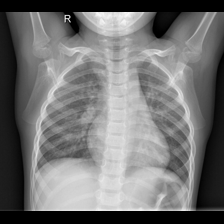

In [6]:
# sample 이미지 확인하기
sample_path = os.path.join(TRAIN_DIR, df['file_name'][0])   # 첫 번째 이미지의 경로 지정 (폴더 경로 + CSV의 파일 이름)
img = Image.open(sample_path)
img

In [7]:
# 위의 sample 이미지 정보 확인하기
print("이미지 크기(가로, 세로):", img.size)
print("색 형식:", img.mode)

# 이미지 array로 변환
image_array = np.array(img)
print("배열 형태:", image_array.shape)
print("자료형:", image_array.dtype)
print("픽셀값 범위:", image_array.min(), "~", image_array.max())

# 출력 결과(sample 이미지)
# 이미지 크기: 224*224 픽셀
# 색: 흑백 (L: 흑백, RGB: 컬러)
# 배열 형태: (224, 224) 2차원
# 자료형: uint8 => 0 ~ 255 사이의 정수 (0: 검정, 255: 흰색)
# 픽셀값 범위: 샘플이미지는 픽셀이 0~250의 값을 가짐 (가장 어두운 값 0 ~ 가장 밝은 값 250)

이미지 크기(가로, 세로): (224, 224)
색 형식: L
배열 형태: (224, 224)
자료형: uint8
픽셀값 범위: 0 ~ 250


In [ ]:
# 전체 이미지의 크기와 색 형식 확인

# 전체 이미지 경로를 한 번에 만들기
df['image_path'] = [os.path.join(TRAIN_DIR, fname) for fname in df['file_name']]
print(df.head(2))

# 가로, 세로, 색의 형태를 받을 리스트 목록 만들기 
widths, heights, modes = [], [], []

for path in df['image_path']:
    with Image.open(path) as im:   # 이미지를 열고, 다 쓰면 자동으로 닫기
        widths.append(im.size[0])  # 가로
        heights.append(im.size[1]) # 세로
        modes.append(im.mode)      # 색 형식

df['width'] = widths
df['height'] = heights
df['mode'] = modes

print("색 형식 분포:\n", df['mode'].value_counts())
print("\n크기 요약:\n", df[['width', 'height']].describe())
print("\n크기 종류:\n", df.groupby(['width','height']).size())

# 출력 결과
# 색 형식 분포: L (모두 흑백)
# 크기 요약: 모든 이미지 224*224 
# 크기 종류: 모든 이미지 224*224, 5,216장

        file_name  label                                         image_path
0  train_0001.png      0  /Users/mac/Desktop/deep_learning/chest_xray/tr...
1  train_0002.png      0  /Users/mac/Desktop/deep_learning/chest_xray/tr...
색 형식 분포:
 mode
L    5216
Name: count, dtype: int64

크기 요약:
         width  height
count  5216.0  5216.0
mean    224.0   224.0
std       0.0     0.0
min     224.0   224.0
25%     224.0   224.0
50%     224.0   224.0
75%     224.0   224.0
max     224.0   224.0

크기 종류:
 width  height
224    224       5216
dtype: int64


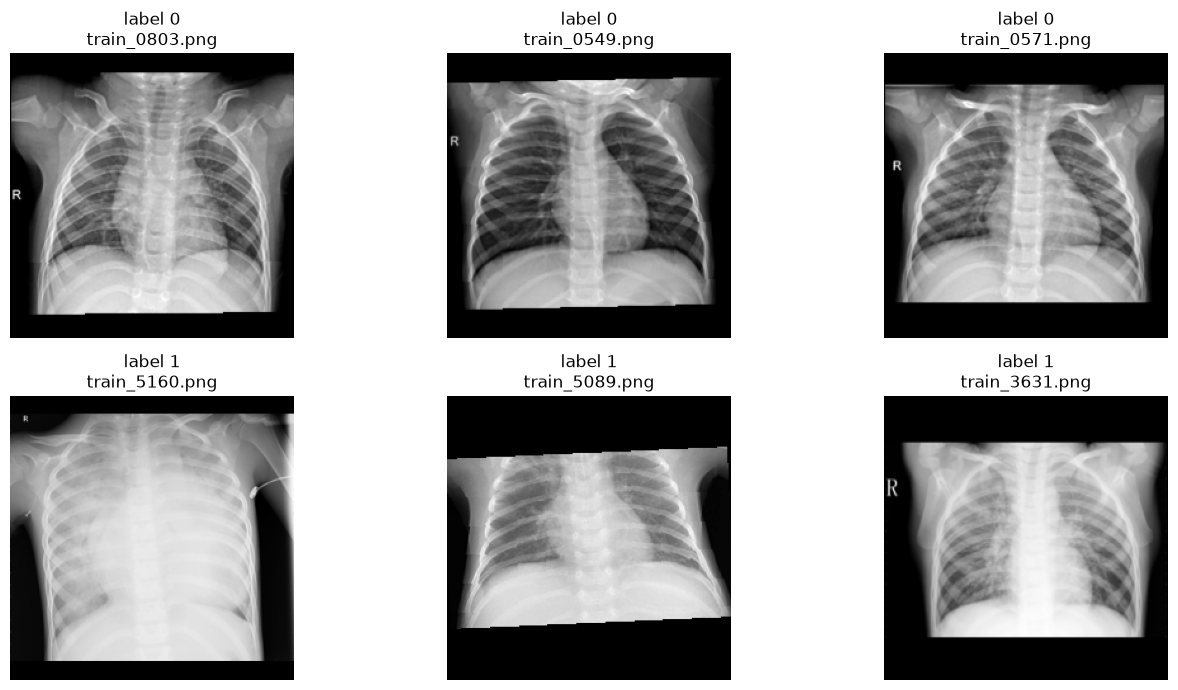

In [9]:
# 정상과 폐렴 샘플 비교

# label별 sample 이미지 비교( label: 0 - 3장, label: 1 - 3장)
label0_paths = df[df['label'] == 0]['image_path'].sample(3, random_state=42).tolist()
label1_paths = df[df['label'] == 1]['image_path'].sample(3, random_state=42).tolist()

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for i, path in enumerate(label0_paths):
    axes[0, i].imshow(Image.open(path), cmap='gray')
    axes[0, i].set_title(f"label 0\n{os.path.basename(path)}")
    axes[0, i].axis('off')

for i, path in enumerate(label1_paths):
    axes[1, i].imshow(Image.open(path), cmap='gray')
    axes[1, i].set_title(f"label 1\n{os.path.basename(path)}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

# 출력결과
# label 0 = 정상, label 1 = 폐렴
# 이미지 가장자리에 검은 여백 존재
# 일부 이미지 회전되어 있음
# R(오른쪽 표시), 전극선 등 이물질 존재

# 1-2). 이미지 데이터 결과 확인

1) train 이미지 기본 정보 
    - 전체 이미지: 5,216장
    - 이미지 크기: 224*224(전체 동일)
    - 색 형식: L (흑백, 1채널)
    - 자료형: unit 8 (픽셀값 0 ~ 255, 0: 검정, 255: 흰색)
    - label 0 = 정상, label 1 = 폐렴

2) train 이미지 특이 사항
    - 이미지 가장자리에 검은 여백 존재
    - 일부 이미지 회전되어 있음
    - R(오른쪽 표시), 전극선 등 이물질 존재

3) train 이미지 처리시 주의할 점
    - 이미지 크기는 통일되어 있음
    - 학습전 픽셀값 정규화 필요( 0~255 -> 0~1)
    - ResNet 학습전 1채널 -> 3채널로 복제 필요함
    - 모델이 여백, R표시, 전극선 등을 단서로 학습할 위험 -> Grad-CAM으로 확인 필요



In [ ]:
# test 데이터, 제출 양식 확인
test_df = pd.read_csv(TEST_CSV_PATH)
submit_df = pd.read_csv(SUBMIT_PATH)

print("test.csv:", test_df.shape)
print(test_df.head(), "\n")

print("sample_submission.csv:", submit_df.shape)
print(submit_df.head(), "\n")

# test 이미지 파일과 CSV 매칭 확인
test_files = sorted([f for f in os.listdir(TEST_DIR) if f.endswith(".png")])
print("test 폴더 이미지 수:", len(test_files))
print("CSV에는 있으나 이미지 폴더에 없는 파일:", len(set(test_df['file_name']) - set(test_files)))
print("이미지 폴더에는 있으나 CSV에는 없는 파일:", len(set(test_files) - set(test_df['file_name'])))

# 출력 결과
# test.csv: 624개, file_name 컬럼만 존재 (label 없음)
# sample_submission.csv: file_name, label 컬럼 → label에 0(정상) 또는 1(폐렴)을 채워 제출
# test 이미지 624장, CSV와 정확히 매칭


test.csv: (624, 1)
       file_name
0  test_0001.png
1  test_0002.png
2  test_0003.png
3  test_0004.png
4  test_0005.png 

sample_submission.csv: (624, 2)
       file_name  label
0  test_0001.png      0
1  test_0002.png      0
2  test_0003.png      0
3  test_0004.png      0
4  test_0005.png      0 

test 폴더 이미지 수: 624
CSV에는 있으나 이미지 폴더에 없는 파일: 0
이미지 폴더에는 있으나 CSV에는 없는 파일: 0


# 2. 학습 준비
1) 재현성 확보
2) 데이터 분할
    - 학습:검증 = 8:2, label 비율을 유지해 분할(stratify)
    - 분할 결과를 저장해 모든 학습에서 같은 검증 데이터 사용
3) 데이터셋 만들기 (Dataset, DataLoader)
3) 평가 지표
    - 평가지표: Accuracy
    - 기타지표: Recall, F1, AUC, Specificity(특이도)
    - 모든 학습 모델의 성능을 같은 기준으로 평가하기 위함

In [11]:
# 라이브러리 호출
import random                                         # seed 고정을 위함
import torch                                          # pytorch 라이브러리
import torch.nn as nn                                 # 신경망 층
from torch.utils.data import Dataset, DataLoader      # 데이터셋 구성
from torchvision import transforms                    # 이미지 전처리
from sklearn.model_selection import train_test_split  # 학습/검증 데이터 분할
from sklearn import metrics                           # 평가 지표

In [12]:
# 2-1) 재현성 확보

# seed 고정
SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
set_seed(SEED)

# 연산 장치 선택
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print("사용 장치:", device)

사용 장치: mps


In [14]:
# 2-2) 데이터 분할(층화분할)
X = df['image_path']  # 입력: 이미지 경로
y = df['label']       # 정답: label (0 정상, 1 폐렴)

x_train, x_val, y_train, y_val = train_test_split(
    X, y,
    test_size = 0.2,     # 80:20 학습/검증 데이터 분할
    stratify = y,        # label 비율 유지
    random_state = SEED  # 매번 같은 분할
)

print("학습 데이터 수:", len(x_train), "검증 데이터 수:", len(x_val))
print("학습 라벨 비율:\n", y_train.value_counts(normalize=True).round(3))
print("검증 라벨 비율:\n", y_val.value_counts(normalize=True).round(3))


학습 데이터 수: 4172 검증 데이터 수: 1044
학습 라벨 비율:
 label
1    0.743
0    0.257
Name: proportion, dtype: float64
검증 라벨 비율:
 label
1    0.743
0    0.257
Name: proportion, dtype: float64


In [16]:
# 2-3) 데이터셋 준비

# 이미지를 모델이 읽을 수 있도록 텐서로 변환
# ToTensor: (224, 224) 2차원 → (1, 224, 224) 3차원, 픽셀값 ÷ 255 → 0~1 스케일링
transform = transforms.Compose([
    transforms.ToTensor()
])

# Train Dataset 생성 
class XrayDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths.tolist()        # 이미지 경로 목록
        self.labels = labels.tolist()      # label 목록
        self.transform = transform         # 변환 규칙

    def __len__(self):
        return len(self.paths)             # 전체 데이터 개수

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('L')   # idx번째 이미지를 흑백으로 열기
        if self.transform:
            img = self.transform(img)                     # 이미지를 텐서로 변환
        label = torch.tensor(self.labels[idx], dtype=torch.float32)  # label을 텐서로 변환
        return img, label

train_dataset = XrayDataset(x_train, y_train, transform=transform)
val_dataset   = XrayDataset(x_val,   y_val,   transform=transform)

print("학습 데이터 수:", len(train_dataset))
print("검증 데이터 수:", len(val_dataset))

# Train DataLoader 생성
g = torch.Generator()
g.manual_seed(SEED)   # 섞는 순서 고정 (재현성)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,  generator=g)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False)


# TEST Dataset 생성
test_df['image_path'] = [os.path.join(TEST_DIR, fname) for fname in test_df['file_name']]

class XrayTestDataset(Dataset):
    def __init__(self, paths, file_names, transform=None):
        self.paths = paths.tolist()            # 이미지 경로 목록
        self.file_names = file_names.tolist()  # 파일 이름 목록 (제출 파일 작성용)
        self.transform = transform             # 변환 규칙 

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('L')
        if self.transform:
            img = self.transform(img)
        return img, self.file_names[idx]     

# TEST DataLoader 생성
test_dataset = XrayTestDataset(test_df['image_path'], test_df['file_name'], transform=transform)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)   # 제출 순서 유지

print("테스트 데이터 수:", len(test_dataset))
print("테스트 배치 수:", len(test_loader))

학습 데이터 수: 4172
검증 데이터 수: 1044
테스트 데이터 수: 624
테스트 배치 수: 20


In [17]:
# 2-4) 평가지표
def evaluate(y_true, y_pred, y_prob, show=True):
    report = metrics.classification_report(y_true, y_pred, output_dict=True)
    if show:
        print(metrics.classification_report(y_true, y_pred, target_names=['정상(0)', '폐렴(1)'], digits=4))
        print("혼동행렬:\n", metrics.confusion_matrix(y_true, y_pred))
    return {
        'Accuracy'           : round(report['accuracy'], 4),
        'Recall(민감도)'      : round(report['1']['recall'], 4),
        'Specificity(특이도)' : round(report['0']['recall'], 4),
        'F1'                 : round(report['1']['f1-score'], 4),
        'AUC'                : round(metrics.roc_auc_score(y_true, y_prob), 4),
    }

# 3. Baseline 구축 
1) Baseline CNN 모델 
